# SpaceX Falcon 9 Machine Learning Prediction
This notebook builds, tunes, and evaluates four classification algorithms (Logistic Regression, Support Vector Machine, Decision Tree, K-Nearest Neighbors) using 10-fold cross-validation GridSearchCV to predict first stage landing outcomes.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix

# Load datasets
X = pd.read_csv('../data/dataset_part_3.csv')
Y = pd.read_csv('../data/dataset_part_2.csv')['Class'].to_numpy()
print('Features shape:', X.shape, '| Target shape:', Y.shape)

Features shape: (90, 80) | Target shape: (90,)


## 1. Feature Standardization & Train/Test Split
Standardize features with `StandardScaler` and split data 80% train / 20% test with `random_state=2`.

In [2]:
transform = StandardScaler()
X_scaled = transform.fit_transform(X)

X_train, X_test, Y_train, Y_test = train_test_split(X_scaled, Y, test_size=0.2, random_state=2)
print(f'Train samples: {X_train.shape[0]}, Test samples: {X_test.shape[0]}')

Train samples: 72, Test samples: 18


## 2. Model 1: Logistic Regression
Tune regularization `C` using 10-fold cross-validation.

In [3]:
lr_parameters = {'C': [0.01, 0.1, 1], 'penalty': ['l2'], 'solver': ['lbfgs']}
lr = LogisticRegression()
logreg_cv = GridSearchCV(lr, lr_parameters, cv=10)
logreg_cv.fit(X_train, Y_train)
print('Tuned hyperparameters (best parameters):', logreg_cv.best_params_)
print('Train CV accuracy:', logreg_cv.best_score_)
lr_acc = logreg_cv.score(X_test, Y_test)
print('Test accuracy:', lr_acc)

Tuned hyperparameters (best parameters): {'C': 1, 'penalty': 'l2', 'solver': 'lbfgs'}
Train CV accuracy: 0.8214285714285714
Test accuracy: 0.8333333333333334


C:\Users\Freiweiss\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\Freiweiss\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warning

## 3. Model 2: Support Vector Machine (SVM)
Tune kernels and hyperparameters `C` and `gamma`.

In [4]:
svm_parameters = {'kernel': ['linear', 'rbf', 'sigmoid'], 'C': np.logspace(-3, 3, 5), 'gamma': np.logspace(-3, 3, 5)}
svm = SVC()
svm_cv = GridSearchCV(svm, svm_parameters, cv=10)
svm_cv.fit(X_train, Y_train)
print('Tuned hyperparameters:', svm_cv.best_params_)
print('Train CV accuracy:', svm_cv.best_score_)
svm_acc = svm_cv.score(X_test, Y_test)
print('Test accuracy:', svm_acc)

Tuned hyperparameters: {'C': np.float64(1.0), 'gamma': np.float64(0.03162277660168379), 'kernel': 'sigmoid'}
Train CV accuracy: 0.8482142857142858
Test accuracy: 0.8333333333333334


## 4. Model 3: Decision Tree Classifier
Tune tree depth, splitting criteria, and minimum sample leaves.

In [5]:
tree_parameters = {
    'criterion': ['gini', 'entropy'],
    'splitter': ['best', 'random'],
    'max_depth': [2 * n for n in range(1, 10)],
    'max_features': ['sqrt'],
    'min_samples_leaf': [1, 2, 4],
    'min_samples_split': [2, 5, 10]
}
tree = DecisionTreeClassifier(random_state=42)
tree_cv = GridSearchCV(tree, tree_parameters, cv=10)
tree_cv.fit(X_train, Y_train)
print('Tuned hyperparameters:', tree_cv.best_params_)
print('Train CV accuracy:', tree_cv.best_score_)
tree_acc = tree_cv.score(X_test, Y_test)
print('Test accuracy:', tree_acc)

Tuned hyperparameters: {'criterion': 'gini', 'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 10, 'splitter': 'random'}
Train CV accuracy: 0.8196428571428571
Test accuracy: 0.6666666666666666


## 5. Model 4: K-Nearest Neighbors (KNN)
Tune `n_neighbors` and distance metrics.

In [6]:
knn_parameters = {'n_neighbors': list(range(1, 11)), 'algorithm': ['auto', 'ball_tree', 'kd_tree', 'brute'], 'p': [1, 2]}
knn = KNeighborsClassifier()
knn_cv = GridSearchCV(knn, knn_parameters, cv=10)
knn_cv.fit(X_train, Y_train)
print('Tuned hyperparameters:', knn_cv.best_params_)
print('Train CV accuracy:', knn_cv.best_score_)
knn_acc = knn_cv.score(X_test, Y_test)
print('Test accuracy:', knn_acc)

Tuned hyperparameters: {'algorithm': 'auto', 'n_neighbors': 6, 'p': 1}
Train CV accuracy: 0.8339285714285714
Test accuracy: 0.8333333333333334


## 6. Model Comparison & Confusion Matrices
Compare the evaluation scores of all 4 models and plot confusion matrices.

                 Model  Train_CV_Accuracy  Test_Accuracy
0  Logistic Regression           0.821429       0.833333
1                  SVM           0.848214       0.833333
2        Decision Tree           0.819643       0.666667
3                  KNN           0.833929       0.833333


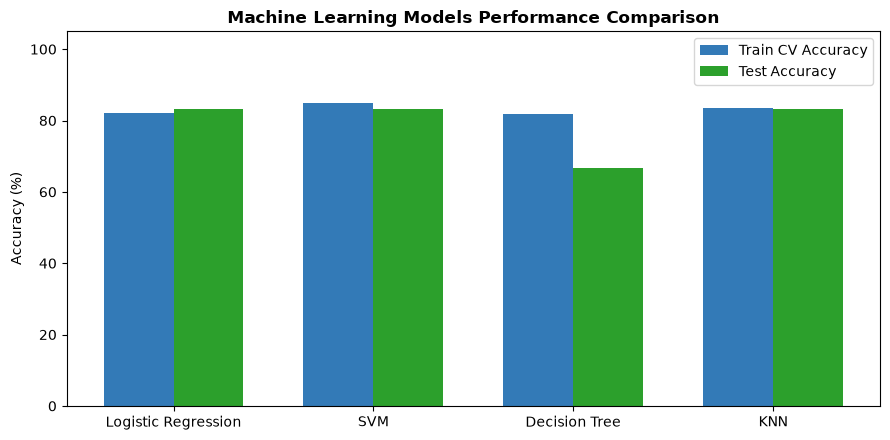

In [7]:
models = ['Logistic Regression', 'SVM', 'Decision Tree', 'KNN']
train_scores = [logreg_cv.best_score_, svm_cv.best_score_, tree_cv.best_score_, knn_cv.best_score_]
test_scores = [lr_acc, svm_acc, tree_acc, knn_acc]

df_perf = pd.DataFrame({'Model': models, 'Train_CV_Accuracy': train_scores, 'Test_Accuracy': test_scores})
print(df_perf)

# Bar chart comparison
plt.figure(figsize=(9, 4.5))
x = np.arange(len(models))
w = 0.35
plt.bar(x - w/2, [s*100 for s in train_scores], width=w, label='Train CV Accuracy', color='#337ab7')
plt.bar(x + w/2, [s*100 for s in test_scores], width=w, label='Test Accuracy', color='#2ca02c')
plt.xticks(x, models, fontsize=10)
plt.ylabel('Accuracy (%)')
plt.title('Machine Learning Models Performance Comparison', fontsize=12, fontweight='bold')
plt.ylim(0, 105)
plt.legend()
plt.tight_layout()
plt.show()

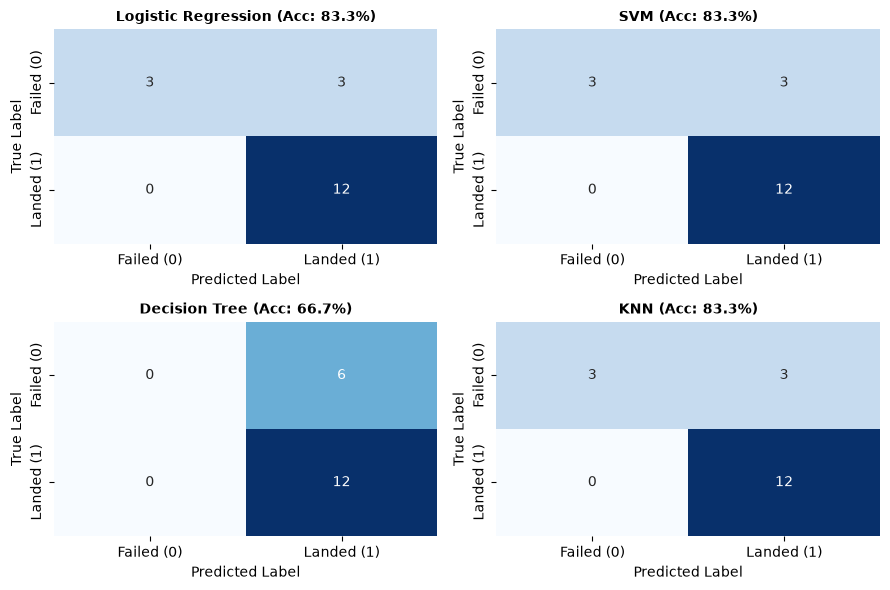

In [8]:
# Confusion Matrices
fig, axes = plt.subplots(2, 2, figsize=(9, 6))
model_preds = [
    ('Logistic Regression', logreg_cv.predict(X_test), lr_acc),
    ('SVM', svm_cv.predict(X_test), svm_acc),
    ('Decision Tree', tree_cv.predict(X_test), tree_acc),
    ('KNN', knn_cv.predict(X_test), knn_acc)
]
for idx, (name, y_pred, acc) in enumerate(model_preds):
    ax = axes.flatten()[idx]
    cm = confusion_matrix(Y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['Failed (0)', 'Landed (1)'], yticklabels=['Failed (0)', 'Landed (1)'])
    ax.set_title(f'{name} (Acc: {acc*100:.1f}%)', fontsize=10, fontweight='bold')
    ax.set_xlabel('Predicted Label')
    ax.set_ylabel('True Label')
plt.tight_layout()
plt.show()